# EDA: FAA Wildlife Strike Database

Dataset: faa_aws.csv, 316 839 reports of wildlife (bird and animal) strikes with civil aircraft in the USA, 1990-2025, 101 columns.
The file is downloaded from Google Drive by data_loader.py (homework 2) into the data folder.

Homework 6: the charts are drawn with seaborn, matplotlib is used only for figure size and titles. New charts were added where a picture shows a data problem better than a table.

Goal: I evaluate the quality of the raw source before building an ETL pipeline on top of it, not the business value of the data. For every check I answer three questions: what is wrong, how much of it there is, and what the pipeline should do about it.

Plan:

1. Source and context
2. Structural check
3. Integrity and completeness
4. Semantic analysis
5. Outliers and anomalies
6. Relationships and consistency
7. Data quality metrics
8. Recommendations for the ETL pipeline
9. Conclusions

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt  # only figure size, titles and layout, the charts themselves are drawn by seaborn
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="muted")

# the notebook is run from notebooks/ (VS Code and Jupyter do this by default), the repo root is one level up
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))
from data_loader import download_dataset

# relative path on purpose, so the output doesn't show the local folder
csv_path = download_dataset(Path(os.path.relpath(ROOT / "data" / "faa_aws.csv")))
df = pd.read_csv(csv_path, low_memory=False)
print(df.shape)

File ../data/faa_aws.csv already exists, skipping download


(316839, 101)


In [2]:
df.head(3)

,INDEX_NR,INCIDENT_DATE,INCIDENT_MONTH,INCIDENT_YEAR,TIME,TIME_OF_DAY,AIRPORT_ID,AIRPORT,AIRPORT_LATITUDE,AIRPORT_LONGITUDE,RUNWAY,STATE,FAAREGION,LOCATION,OPID,OPERATOR,REG,FLT,AIRCRAFT,AMA,AMO,EMA,EMO,AC_CLASS,AC_MASS,TYPE_ENG,NUM_ENGS,ENG_1_POS,ENG_2_POS,ENG_3_POS,ENG_4_POS,PHASE_OF_FLIGHT,HEIGHT,SPEED,DISTANCE,SKY,PRECIPITATION,AOS,COST_REPAIRS,COST_OTHER,COST_REPAIRS_INFL_ADJ,COST_OTHER_INFL_ADJ,INGESTED_OTHER,INDICATED_DAMAGE,DAMAGE_LEVEL,STR_RAD,DAM_RAD,STR_WINDSHLD,DAM_WINDSHLD,STR_NOSE,DAM_NOSE,STR_ENG1,DAM_ENG1,ING_ENG1,STR_ENG2,DAM_ENG2,ING_ENG2,STR_ENG3,DAM_ENG3,ING_ENG3,STR_ENG4,DAM_ENG4,ING_ENG4,STR_PROP,DAM_PROP,STR_WING_ROT,DAM_WING_ROT,STR_FUSE,DAM_FUSE,STR_LG,DAM_LG,STR_TAIL,DAM_TAIL,STR_LGHTS,DAM_LGHTS,STR_OTHER,DAM_OTHER,OTHER_SPECIFY,EFFECT,EFFECT_OTHER,BIRD_BAND_NUMBER,SPECIES_ID,SPECIES,OUT_OF_RANGE_SPECIES,REMARKS,REMAINS_COLLECTED,REMAINS_SENT,WARNED,NUM_SEEN,NUM_STRUCK,SIZE,ENROUTE_STATE,NR_INJURIES,NR_FATALITIES,COMMENTS,REPORTED_NAME,REPORTED_TITLE,SOURCE,PERSON,LUPDATE,TRANSFER
0,608242,1996-06-22,6,1996,NaN,NaN,KSMF,SACRAMENTO INTL,38.69542,-121.59077,NaN,CA,AWP,NaN,UAL,UNITED AIRLINES,NaN,1768,B-737-300,148,24,10.0,1.0,A,4.0,D,2.0,1.0,1.0,NaN,NaN,Take-off Run,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,NaN,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,UNKBM,Unknown bird - medium,0,BLOOD ON L FWD NOSE AREA SEEN BY CREW AFTER LDG.,0,0,Unknown,NaN,1,Medium,NaN,NaN,NaN,/Legacy Record 100001/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
1,608243,1996-06-26,6,1996,NaN,NaN,KDEN,DENVER INTL AIRPORT,39.85841,-104.667,NaN,CO,ANM,NaN,UAL,UNITED AIRLINES,NaN,1845,B-737-300,148,24,10.0,1.0,A,4.0,D,2.0,1.0,1.0,NaN,NaN,Take-off Run,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,NaN,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,UNKBM,Unknown bird - medium,0,CREW SUSPECTED BIRDSTRIKE ON T/O. LOOKED LIKE ...,0,0,Unknown,NaN,1,Medium,NaN,NaN,NaN,/Legacy Record 100002/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
2,608244,1996-07-01,7,1996,NaN,NaN,KOMA,EPPLEY AIRFIELD,41.30252,-95.89417,NaN,NE,ACE,NaN,UAL,UNITED AIRLINES,NaN,306,B-757-200,148,26,34.0,40.0,A,4.0,D,2.0,1.0,1.0,NaN,NaN,Take-off Run,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,N,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,UNKBM,Unknown bird - medium,0,BIRDSTRIKE AT ROTATION. INSPN. NO DMG.,0,0,Unknown,NaN,1,Medium,NaN,NaN,NaN,/Legacy Record 100003/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0


One row is one strike report. Height is in feet, speed in knots, distance in nautical miles.

## 1. Source and context

dates: 1990-01-02 - 2025-03-21 | not parsed: 0


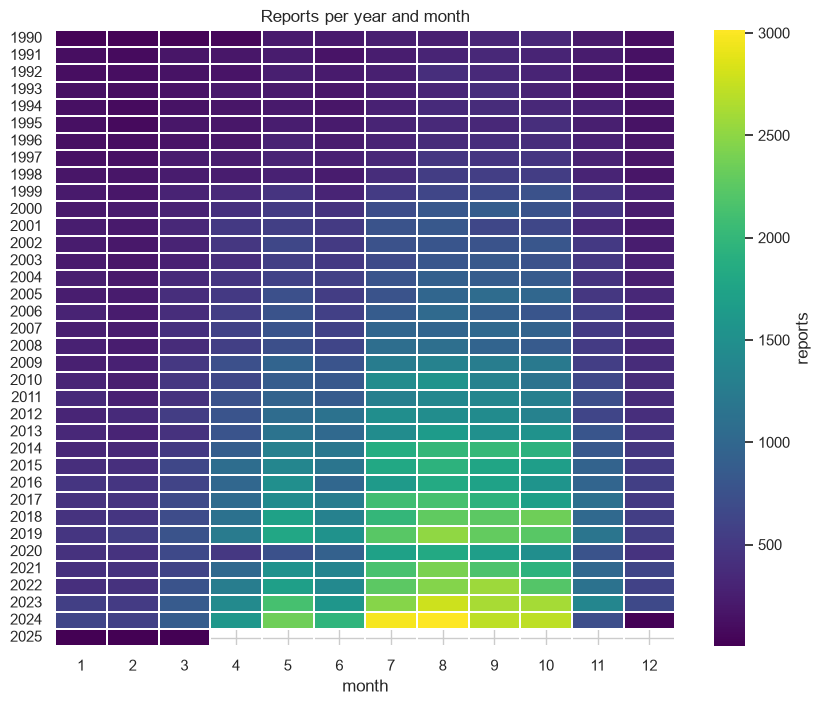

In [3]:
dates = pd.to_datetime(df["INCIDENT_DATE"], errors="coerce")
print("dates:", dates.min().date(), "-", dates.max().date(), "| not parsed:", dates.isna().sum())

# one cell = number of reports in a month: shows the growth, the season and the gaps at once
per_month = df.pivot_table(index="INCIDENT_YEAR", columns="INCIDENT_MONTH", values="INDEX_NR", aggfunc="count")
plt.figure(figsize=(10, 8))
sns.heatmap(per_month, cmap="viridis", linewidths=0.3, cbar_kws={"label": "reports"})
plt.title("Reports per year and month")
plt.xlabel("month")
plt.ylabel("")
plt.show()

In [4]:
months = dates.dt.to_period("M")
all_months = pd.period_range(months.min(), months.max(), freq="M")
print("months without reports:", len(all_months.difference(months.unique())))
print(months.value_counts().sort_index().tail(4))

months without reports: 0
INCIDENT_DATE
2024-12    17
2025-01     7
2025-02     3
2025-03     6
Freq: M, Name: count, dtype: int64


Reports grow from about 2k a year to 20k, probably because more airports report. No empty months.

The heatmap shows two more things. There is a strong season: July-October give about 4 times more reports than December-February (bird migration), so monthly stats must not be compared without the season. And the end of the data is cut: November 2024 has half of the usual reports and December 2024 only 17 instead of about 600, while 2025 has 16 rows in January-March. The export was made before the late reports came in, so the last months are incomplete. The dip in spring 2020 is COVID. I won't use 2024-2025 in yearly counts.

In [5]:
df["SOURCE"].value_counts()

SOURCE
FAA Form 5200-7-E       193617
FAA Form 5200-7          41775
Multiple                 35176
Air Transport Report     17152
MOR                      14456
Airport Report            7337
Other                     2292
Daily Report              2183
PACIR                      879
Engine Manufacturer        811
AC Incident Rept           715
ASRS                       195
NTSB                       143
AAIPN-1                     67
Transport Canada            37
BASH                         4
Name: count, dtype: int64

The electronic FAA form gives about 61% of reports, the rest come from 15 other sources.

## 2. Structural check

In [6]:
expected = {
    "INCIDENT_DATE": "date", "TIME": "time", "AIRPORT_LATITUDE": "float", "AIRPORT_LONGITUDE": "float",
    "AC_MASS": "int", "NUM_ENGS": "int", "HEIGHT": "float", "SPEED": "float",
    "INDICATED_DAMAGE": "bool", "NUM_SEEN": "int", "NUM_STRUCK": "int", "LUPDATE": "date",
}
pd.DataFrame({"expected": expected, "actual": df[list(expected)].dtypes.astype(str)})

,expected,actual
INCIDENT_DATE,date,object
TIME,time,object
AIRPORT_LATITUDE,float,object
AIRPORT_LONGITUDE,float,object
AC_MASS,int,float64
NUM_ENGS,int,float64
HEIGHT,float,float64
SPEED,float,float64
INDICATED_DAMAGE,bool,int64
NUM_SEEN,int,object


Coordinates were read as text, so something non-numeric is inside. NUM_SEEN and NUM_STRUCK are ranges like 2-10, not numbers. Mass and number of engines are float only because of NaN.

In [7]:
lat = pd.to_numeric(df["AIRPORT_LATITUDE"], errors="coerce")
lon = pd.to_numeric(df["AIRPORT_LONGITUDE"], errors="coerce")
bad_coords = (df["AIRPORT_LATITUDE"].notna() & lat.isna()) | (df["AIRPORT_LONGITUDE"].notna() & lon.isna())
df.loc[bad_coords, ["AIRPORT_ID", "STATE", "AIRPORT_LATITUDE", "AIRPORT_LONGITUDE"]]

,AIRPORT_ID,STATE,AIRPORT_LATITUDE,AIRPORT_LONGITUDE
254140,LKTB,FN,49°09'05?N,16°41'40?E
254931,LTFM,FN,41°15'44?N 28°,NaN
256726,PALP,AK,"70.3442778,-15",-150.94475
269181,KBKT,VA,"37.0747673,-77",-77.9565984
299588,PAVE,AK,"67.0086750,-14",-146.3663583
304282,KBUU,WI,"42.6907171,-88","42.6907171,-88"
316155,MUGM,FN,N19°54.39',W75°12.42'


7 rows with coordinates in other formats (degrees and minutes, two numbers in one cell). They need to be converted or set to NaN.

In [8]:
print("INDEX_NR unique:", df["INDEX_NR"].is_unique)

constant = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("constant columns:", {c: str(df[c].iloc[0]) for c in constant})

INDEX_NR unique: True


constant columns: {'REPORTED_NAME': 'REDACTED', 'REPORTED_TITLE': 'REDACTED', 'TRANSFER': '0'}


INDEX_NR is a proper key. REPORTED_NAME, REPORTED_TITLE and TRANSFER have one value for all rows, they can be dropped.

In [9]:
text = df.select_dtypes("object")
spaces = pd.DataFrame({
    "blank": text.apply(lambda s: s.str.strip().eq("").sum()),
    "extra spaces": text.apply(lambda s: (s.dropna() != s.dropna().str.strip()).sum()),
})
spaces[spaces.sum(axis=1) > 0].sort_values("extra spaces", ascending=False).head(8)

,blank,extra spaces
AC_CLASS,0,226557
COMMENTS,0,61963
REMARKS,2,21545
TIME,14105,14105
AIRCRAFT,0,965
RUNWAY,0,289
OTHER_SPECIFY,0,151
AIRPORT,0,93


In [10]:
print(df["AC_CLASS"].dropna().unique())
print(df["TIME"].value_counts().head(3))

['A  ' 'B  ' 'J  ' 'C  ' 'Y  ']
TIME
         14105
08:00     1799
09:00     1787
Name: count, dtype: int64


AC_CLASS has trailing spaces, so a filter on 'A' finds nothing. TIME has 14 105 values that are only spaces, isna() doesn't count them.

## 3. Integrity and completeness

50 of 101 columns have NaN


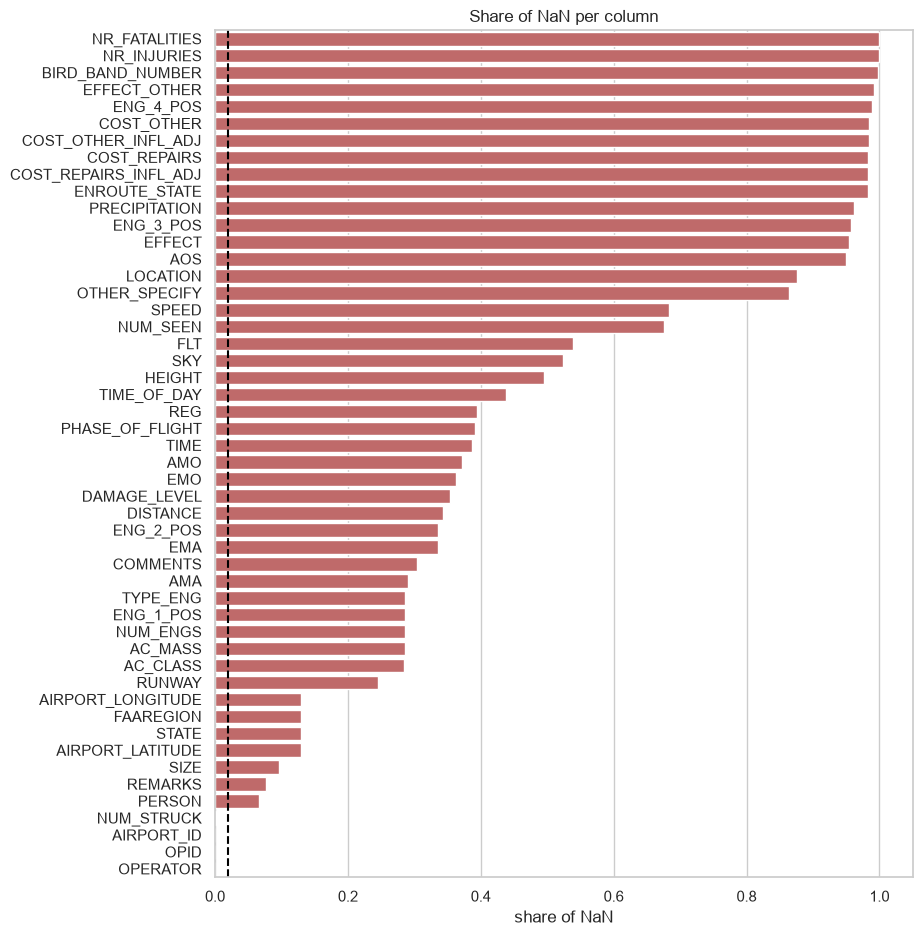

In [11]:
missing = df.isna().mean()
missing = missing[missing > 0].sort_values(ascending=False)
print(len(missing), "of", df.shape[1], "columns have NaN")

plt.figure(figsize=(9, 11))
ax = sns.barplot(x=missing.values, y=missing.index, color="indianred")
ax.axvline(0.02, color="black", linestyle="--")
ax.set(title="Share of NaN per column", xlabel="share of NaN", ylabel="")
plt.show()

50 columns have gaps. Some of them are fine to be empty: costs, effect, injuries are filled only when something happened. But time, flight phase, height, speed and aircraft info should be in every report and they are often missing.

The four columns at the bottom (NUM_STRUCK, AIRPORT_ID, OPID, OPERATOR) look almost complete, but below I show that their gaps are hidden behind placeholders.

In [12]:
for k in [3, 4]:
    has_engine = df["NUM_ENGS"] >= k
    print(f"ENG_{k}_POS filled: {df.loc[has_engine, f'ENG_{k}_POS'].notna().mean():.0%} where needed, "
          f"{df.loc[~has_engine, f'ENG_{k}_POS'].notna().sum()} where not needed")

ENG_3_POS filled: 100% where needed, 0 where not needed
ENG_4_POS filled: 100% where needed, 0 where not needed


Engine 3 and 4 positions are filled exactly for aircraft that have these engines, so these gaps are ok.

Missing values also hide behind placeholders:

In [13]:
time_blank = df["TIME"].str.strip().eq("")
hidden = pd.Series({
    "TIME is blank": time_blank.sum(),
    "AIRPORT_ID = ZZZZ": (df["AIRPORT_ID"] == "ZZZZ").sum(),
    "OPID = UNK": (df["OPID"] == "UNK").sum(),
    "AIRCRAFT unknown": df["AIRCRAFT"].str.contains("UNKNOWN", na=False).sum(),
    "SPECIES unknown": df["SPECIES"].str.contains("Unknown", na=False).sum(),
    "WARNED = Unknown": (df["WARNED"] == "Unknown").sum(),
})
pd.DataFrame({"rows": hidden, "share": (hidden / len(df)).round(3)})

,rows,share
TIME is blank,14105,0.045
AIRPORT_ID = ZZZZ,40858,0.129
OPID = UNK,89606,0.283
AIRCRAFT unknown,89889,0.284
SPECIES unknown,125555,0.396
WARNED = Unknown,196397,0.620


13% of airports, 28% of operators and aircraft and 40% of species are unknown. For a species analysis only about 60% of rows can be used.

In [14]:
cols = ["TIME", "TIME_OF_DAY", "PHASE_OF_FLIGHT", "HEIGHT", "SPEED", "SKY", "AC_CLASS", "COMMENTS"]
period = pd.cut(df["INCIDENT_YEAR"], [1989, 1999, 2009, 2019, 2025], labels=["1990s", "2000s", "2010s", "2020s"])

na = df[cols].isna()
na["TIME"] |= time_blank
(na.groupby(period, observed=True).mean() * 100).round().astype(int).T

INCIDENT_YEAR,1990s,2000s,2010s,2020s
TIME,89,55,42,18
TIME_OF_DAY,26,39,46,51
PHASE_OF_FLIGHT,20,33,42,46
HEIGHT,28,41,52,59
SPEED,49,61,70,78
SKY,36,48,54,60
AC_CLASS,13,22,32,34
COMMENTS,15,8,18,75


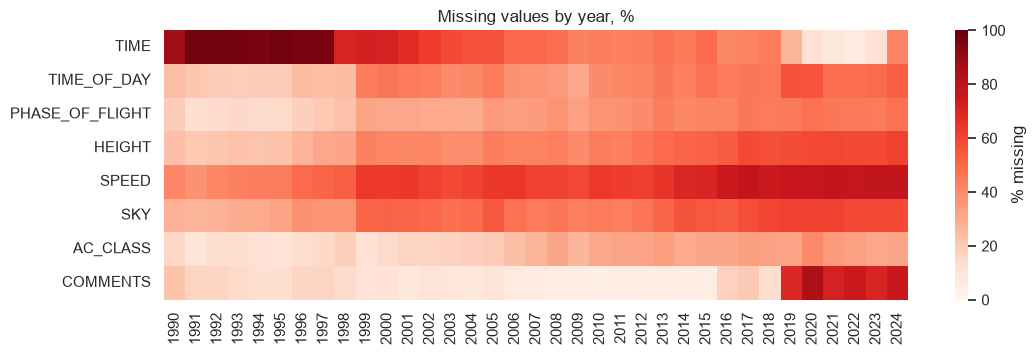

In [15]:
yearly_na = (na.groupby(df["INCIDENT_YEAR"]).mean() * 100).loc[:2024]  # 2025 has only 16 rows

plt.figure(figsize=(12, 3.5))
sns.heatmap(yearly_na.T, cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% missing"})
plt.title("Missing values by year, %")
plt.xlabel("")
plt.show()

The table by decade and the heatmap by year agree:

- TIME was almost never filled before 1998 and is nearly complete in 2019-2023;
- SPEED, HEIGHT and SKY get worse year by year: there are more short reports where a carcass was just found on the runway;
- COMMENTS jump from 5-20% missing to 70-85% in 2019. Such a step in one year looks like a change in the source (a new form or export), not in the reporters, so it is worth asking the data owner;
- 2024 is worse in TIME again, probably because recent reports are not finished yet.

In [16]:
content = df.drop(columns="INDEX_NR")
in_groups = content.duplicated(keep=False)  # every row that has a twin, the first one too
extra = content.duplicated()                # only the repeats, the first one is kept

print("full duplicates:", df.duplicated().sum())
print("groups of repeated reports:", (in_groups & ~extra).sum())
print("rows in these groups:", in_groups.sum())
print("extra copies to remove:", extra.sum())
df.loc[in_groups, ["INDEX_NR", "INCIDENT_DATE", "AIRPORT_ID", "SPECIES", "SOURCE"]].head(4)

full duplicates: 0
groups of repeated reports: 55
rows in these groups: 116
extra copies to remove: 61


,INDEX_NR,INCIDENT_DATE,AIRPORT_ID,SPECIES,SOURCE
189016,895794,2019-07-07,KTPA,American kestrel,FAA Form 5200-7-E
189017,895797,2019-07-07,KTPA,American kestrel,FAA Form 5200-7-E
190117,921811,2019-08-30,KDFW,Mourning dove,FAA Form 5200-7-E
190118,921812,2019-08-30,KDFW,Mourning dove,FAA Form 5200-7-E


55 reports were sent more than once, with a new id each time, which gives 116 rows. If I keep one row per group, 61 extra copies have to be removed.

In [17]:
for code_col, name_col in [("AIRPORT_ID", "AIRPORT"), ("SPECIES_ID", "SPECIES"), ("OPID", "OPERATOR")]:
    pairs = df[[code_col, name_col]].dropna().drop_duplicates()
    print(f"{code_col}: codes with 2+ names = {pairs[code_col].duplicated().sum()}, "
          f"names with 2+ codes = {pairs[name_col].duplicated().sum()}")

print(df.loc[df["AIRPORT_ID"] == "KTSO", "AIRPORT"].value_counts())

AIRPORT_ID: codes with 2+ names = 1, names with 2+ codes = 1
SPECIES_ID: codes with 2+ names = 0, names with 2+ codes = 0
OPID: codes with 2+ names = 0, names with 2+ codes = 7
AIRPORT
CARROLL COUNTY-TOLSON ARPT       2
CARROLL COUNTY-TOLSON AIRPORT    1
Name: count, dtype: int64


One airport has two spellings and 7 operator names have several codes, so joins should use codes.

## 4. Semantic analysis

In [18]:
for col in ["PHASE_OF_FLIGHT", "DAMAGE_LEVEL", "NUM_STRUCK", "PRECIPITATION", "EFFECT"]:
    print(col, df[col].value_counts().to_dict(), "\n")

PHASE_OF_FLIGHT {'Approach': 81663, 'Landing Roll': 34996, 'Take-off Run': 32486, 'Climb': 28848, 'En Route': 5854, 'Departure': 3413, 'Descent': 2703, 'Local': 1337, 'Arrival': 831, 'Taxi': 733, 'Parked': 115, 'Unknown': 5} 

DAMAGE_LEVEL {'N': 184006, 'M': 8674, 'M?': 7685, 'S': 4337, 'D': 88} 

NUM_STRUCK {'1': 281129, '2-10': 33388, '11-100': 1590, 'More than 100': 57} 

PRECIPITATION {'Rain': 8320, 'Fog': 2610, 'Snow': 581, 'Fog, Rain': 334, 'Rain, Snow': 31, 'Fog, Snow': 17, 'None, Rain': 9, 'Fog, Rain, Snow': 6, 'None, Snow': 6, 'Fog, None': 1} 

EFFECT {'Precautionary Landing': 8659, 'Aborted Take-off': 3131, 'Other': 1962, 'Other, Precautionary Landing': 387, 'Engine Shutdown': 254, 'Engine Shutdown, Precautionary Landing': 220, 'Engine Shutdown, Other, Precautionary Landing': 45, 'Aborted Take-off, Engine Shutdown': 32, 'Engine Shutdown, Other': 14, 'Aborted Take-off, Other': 11} 



M? in damage level means minor but not sure. Flight phase mixes an old and a new list of values. Precipitation and effect keep several values in one cell, and 16 rows say None together with rain or snow.

In [19]:
num_cols = ["HEIGHT", "SPEED", "DISTANCE", "AOS", "COST_REPAIRS", "COST_OTHER"]
df[num_cols].describe(percentiles=[0.5, 0.99]).T.round(1)

,count,mean,std,min,50%,99%,max
HEIGHT,160054.0,875.5,1850.2,0.0,50.0,9000.0,32000.0
SPEED,100411.0,142.8,46.5,0.0,140.0,250.0,541.0
DISTANCE,208014.0,0.9,3.6,0.0,0.0,20.0,99.0
AOS,15758.0,77.0,367.3,0.0,2.5,1800.0,10080.0
COST_REPAIRS,5246.0,137552.4,819827.8,0.0,12000.0,2505260.2,36000000.0
COST_OTHER,5142.0,21272.0,214525.4,0.0,540.0,315000.0,12500000.0


No negative values. 32 000 ft and 541 kt are extreme but possible for a jet. Costs are very skewed: median 12k, max 36M dollars.

In [20]:
ok = dates.notna()
print("month matches date:", (dates[ok].dt.month == df.loc[ok, "INCIDENT_MONTH"]).mean())
print("year matches date:", (dates[ok].dt.year == df.loc[ok, "INCIDENT_YEAR"]).mean())
print("species with 2+ sizes:", (df.groupby("SPECIES_ID")["SIZE"].nunique() > 1).sum())
print("inflation-adjusted cost < nominal:", (df["COST_REPAIRS_INFL_ADJ"] < df["COST_REPAIRS"]).sum())

month matches date: 1.0
year matches date: 1.0
species with 2+ sizes: 0
inflation-adjusted cost < nominal: 0


Month and year match the date, inflation-adjusted costs are fine. Size depends only on the species.

## 5. Outliers and anomalies

In [21]:
rows = []
for col in num_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    rows.append([col, len(s), low, high, ((s < low) | (s > high)).mean().round(3)])

outliers = pd.DataFrame(rows, columns=["column", "filled", "low", "high", "outlier share"]).set_index("column")
outliers

,filled,low,high,outlier share
column,,,,
HEIGHT,160054,-1350.0,2250.0,0.129
SPEED,100411,60.0,220.0,0.092
DISTANCE,208014,0.0,0.0,0.124
AOS,15758,-33.5,58.5,0.142
COST_REPAIRS,5246,-68750.0,121250.0,0.131
COST_OTHER,5142,-7000.0,12200.0,0.159


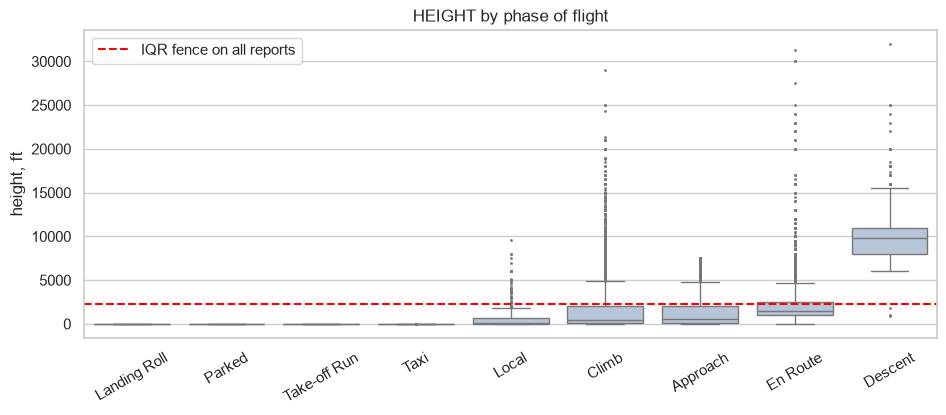

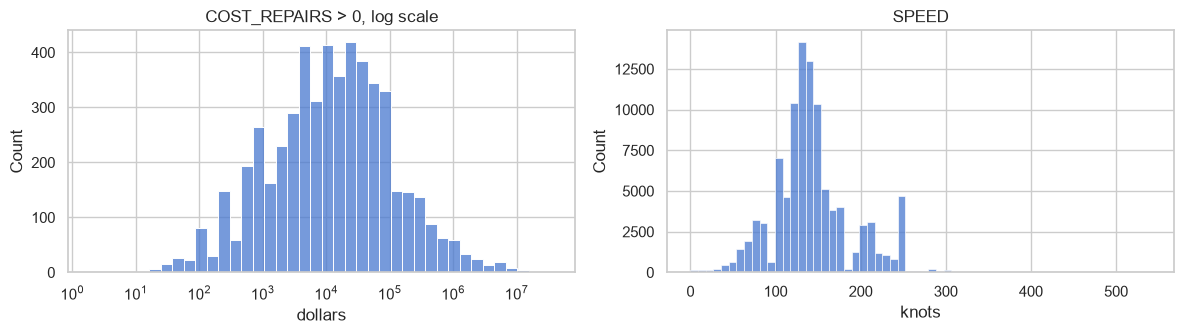

In [22]:
# the IQR fence for HEIGHT is counted on all reports, the boxes are split by flight phase
# Arrival, Departure and Unknown have 0-3 heights, they are left out
heights = df.groupby("PHASE_OF_FLIGHT")["HEIGHT"].agg(["count", "median"])
order = heights[heights["count"] >= 100].sort_values("median").index
plt.figure(figsize=(11, 4))
ax = sns.boxplot(data=df, x="PHASE_OF_FLIGHT", y="HEIGHT", order=order, color="lightsteelblue", fliersize=1)
ax.axhline(outliers.loc["HEIGHT", "high"], color="red", linestyle="--", label="IQR fence on all reports")
ax.set(title="HEIGHT by phase of flight", xlabel="", ylabel="height, ft")
ax.tick_params(axis="x", rotation=30)
ax.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df.loc[df["COST_REPAIRS"] > 0, "COST_REPAIRS"], log_scale=True, bins=40, ax=axes[0])
axes[0].set(title="COST_REPAIRS > 0, log scale", xlabel="dollars")
sns.histplot(df["SPEED"].dropna(), bins=60, ax=axes[1])
axes[1].set(title="SPEED", xlabel="knots")
plt.tight_layout()
plt.show()

IQR marks 9-16% of values as outliers. I don't think it suits this data, the boxplot shows why: the red line is the IQR fence counted on all reports (2 250 ft). Most strikes happen on the ground, so the fence is low and almost every strike in Climb, En Route or Descent becomes an "outlier", while inside one phase the values are normal. A range check per flight phase would work better here.

Repair costs look like a normal bell on a log scale, so they are log-normal and outliers should be searched in log, not in dollars. SPEED has peaks at round values (120, 130, 140, 150) and a separate peak at 250 kt, the speed limit below 10 000 ft: people often write the limit or a rounded number, not the measured speed. So SPEED is approximate, which is ok for analysis but should be documented.

The shares are also counted on different bases: HEIGHT is filled in half of the reports, costs in less than 2%, so the numbers in the table are not really comparable.

In [23]:
df.loc[df["SPEED"] > 400, ["INCIDENT_DATE", "AIRCRAFT", "PHASE_OF_FLIGHT", "HEIGHT", "SPEED"]]

,INCIDENT_DATE,AIRCRAFT,PHASE_OF_FLIGHT,HEIGHT,SPEED
266843,2023-09-14,B-737-900,Descent,32000.0,541.0


In [24]:
print(df.loc[lon > 0, "STATE"].value_counts().to_dict())
df.loc[(lon > 0) & df["STATE"].isin(["AK", "KS"]), ["AIRPORT_ID", "AIRPORT", "STATE", "AIRPORT_LONGITUDE"]].drop_duplicates()

{'FN': 2126, 'MP': 219, 'MH': 12, 'AK': 2, 'UM': 2, 'KS': 1}


,AIRPORT_ID,AIRPORT,STATE,AIRPORT_LONGITUDE
6495,PASY,EARECKSON AIR STATION,AK,174.11333
269063,3AU,AUGUSTA MUNICIPAL AIRPORT,KS,97.0778611


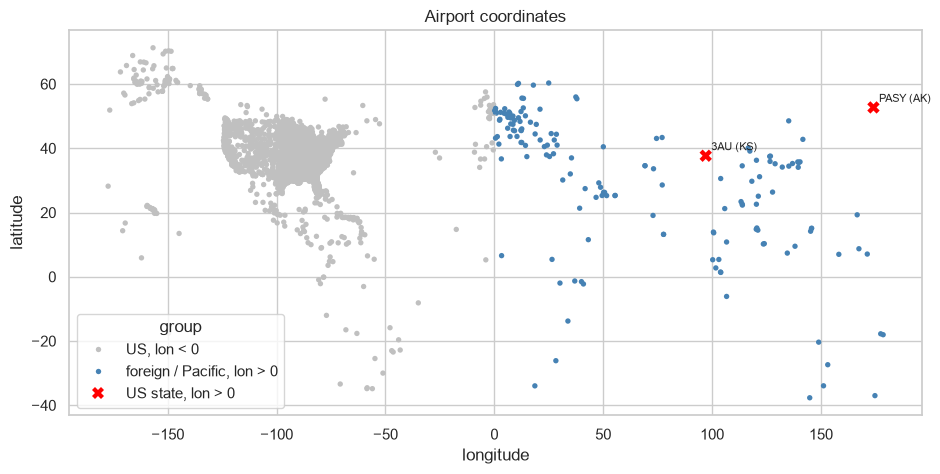

In [25]:
# one point per airport; FN = foreign, MP/MH/UM = US islands in the Pacific, they are east of 0° by nature
airports = pd.DataFrame({"AIRPORT_ID": df["AIRPORT_ID"], "STATE": df["STATE"], "lat": lat, "lon": lon})
airports = airports.dropna(subset=["lat", "lon"]).drop_duplicates("AIRPORT_ID")
east_ok = airports["STATE"].isin(["FN", "MP", "MH", "UM"])
airports["group"] = np.select([airports["lon"] < 0, east_ok], ["US, lon < 0", "foreign / Pacific, lon > 0"],
                              "US state, lon > 0")

plt.figure(figsize=(11, 5))
ax = sns.scatterplot(data=airports, x="lon", y="lat", hue="group", style="group", size="group", linewidth=0,
                     palette={"US, lon < 0": "silver", "foreign / Pacific, lon > 0": "steelblue", "US state, lon > 0": "red"},
                     markers={"US, lon < 0": "o", "foreign / Pacific, lon > 0": "o", "US state, lon > 0": "X"},
                     sizes={"US, lon < 0": 15, "foreign / Pacific, lon > 0": 15, "US state, lon > 0": 80})
for _, a in airports[airports["group"] == "US state, lon > 0"].iterrows():
    ax.annotate(f'{a["AIRPORT_ID"]} ({a["STATE"]})', (a["lon"], a["lat"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.set(title="Airport coordinates", xlabel="longitude", ylabel="latitude")
plt.show()

The 541 kt case is a normal cruise speed. Positive longitude in Alaska is real (an island past 180°). The airport in Kansas with +97 is a sign error, on the map it is mirrored to Asia at the same latitude. All the blue points are foreign airports (FN) and US islands in the Pacific, their positive longitude is correct.

In [26]:
lupdate = pd.to_datetime(df["LUPDATE"])
updated_before = lupdate < dates
print("updated before the incident:", updated_before.sum())

hour = pd.to_datetime(df["TIME"].str.strip(), format="%H:%M", errors="coerce").dt.hour
night_at_noon = (df["TIME_OF_DAY"] == "Night") & hour.between(10, 15)
day_at_night = (df["TIME_OF_DAY"] == "Day") & hour.between(0, 4)
print("'Night' at 10-15h:", night_at_noon.sum(), "| 'Day' at 0-4h:", day_at_night.sum())

updated before the incident: 12
'Night' at 10-15h: 918 | 'Day' at 0-4h: 829


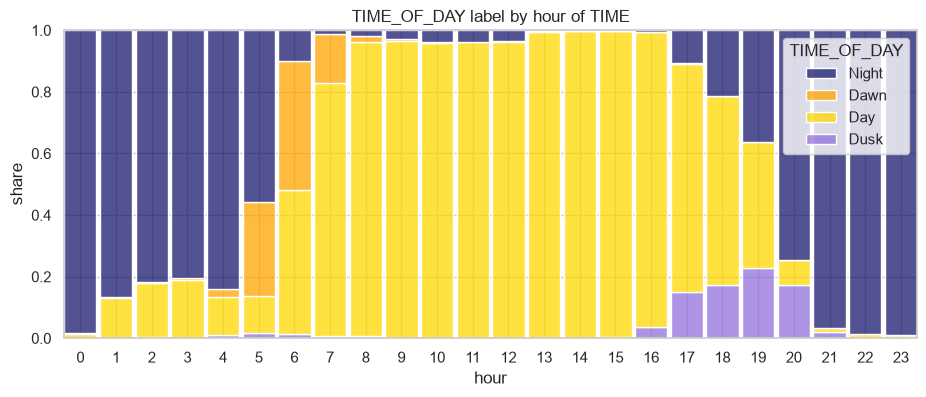

In [27]:
# share of each TIME_OF_DAY label in every hour of TIME
tod = pd.DataFrame({"hour": hour, "TIME_OF_DAY": df["TIME_OF_DAY"]}).dropna()
plt.figure(figsize=(11, 4))
ax = sns.histplot(data=tod, x="hour", hue="TIME_OF_DAY", hue_order=["Night", "Dawn", "Day", "Dusk"],
                  multiple="fill", discrete=True, shrink=0.9,
                  palette={"Night": "midnightblue", "Dawn": "orange", "Day": "gold", "Dusk": "mediumpurple"})
ax.set(title="TIME_OF_DAY label by hour of TIME", xlabel="hour", ylabel="share", xticks=range(24))
plt.show()

12 records were updated before the strike date, which is impossible. 1 747 rows have night at noon or day at 2 am, one of the two fields is wrong.

The chart shows that most of the labels are fine, mistakes at 5-7 and 17-20 are just a border between dawn/dusk and day/night. But the errors are not symmetric: at 1-3 am 13-19% of reports say "Day", while at 1-3 pm "Night" is almost never used. My guess is that part of TIME is written in the 12-hour format without PM (1:00 instead of 13:00). Then TIME_OF_DAY is more reliable than TIME for these rows.

In [28]:
df.groupby("PHASE_OF_FLIGHT")["HEIGHT"].agg(
    reports="count", median="median", max="max", share_zero=lambda s: (s == 0).mean()
).round(2)

,reports,median,max,share_zero
PHASE_OF_FLIGHT,,,,
Approach,61726,500.0,7500.0,0.00
Arrival,3,100.0,210.0,0.00
Climb,22875,400.0,29000.0,0.00
Departure,0,NaN,NaN,0.00
Descent,1622,9862.5,32000.0,0.00
En Route,4737,1500.0,31300.0,0.00
Landing Roll,34996,0.0,0.0,1.00
Local,427,100.0,9600.0,0.07
Parked,115,0.0,0.0,1.00


Phase and height agree: zero on the ground, not zero in the air.

## 6. Relationships and consistency

In [29]:
parts = ["RAD", "WINDSHLD", "NOSE", "ENG1", "ENG2", "ENG3", "ENG4", "PROP",
         "WING_ROT", "FUSE", "LG", "TAIL", "LGHTS", "OTHER"]
dam = df[[f"DAM_{p}" for p in parts]].to_numpy()
struck = df[[f"STR_{p}" for p in parts]].to_numpy()
any_damage = dam.max(axis=1)

print(pd.crosstab(df["INDICATED_DAMAGE"], df["DAMAGE_LEVEL"].fillna("NaN")), "\n")
print("INDICATED_DAMAGE == any DAM_*:", (df["INDICATED_DAMAGE"] == any_damage).mean())

DAMAGE_LEVEL       D     M    M?       N     NaN     S
INDICATED_DAMAGE                                      
0                  0     0     0  184006  112047     0
1                 88  8674  7685       0       2  4337 

INDICATED_DAMAGE == any DAM_*: 1.0


The damage flags agree with each other. Next check: a part can't be damaged if it wasn't struck.

In [30]:
ing = df[["ING_ENG1", "ING_ENG2", "ING_ENG3", "ING_ENG4"]].to_numpy()
str_eng = df[["STR_ENG1", "STR_ENG2", "STR_ENG3", "STR_ENG4"]].to_numpy()

damaged_not_struck = (dam > struck).any(axis=1)
ingested_not_struck = (ing > str_eng).any(axis=1)
print("damaged, not struck:", damaged_not_struck.sum())
print("ingested, not struck:", ingested_not_struck.sum())

wrong_engine = ((df["STR_ENG2"] == 1) & (df["NUM_ENGS"] < 2)) | ((df["STR_ENG3"] == 1) & (df["NUM_ENGS"] < 3)) \
               | ((df["STR_ENG4"] == 1) & (df["NUM_ENGS"] < 4))
print("strike on an engine the aircraft doesn't have:", wrong_engine.sum())

damaged, not struck: 394
ingested, not struck: 66
strike on an engine the aircraft doesn't have: 14


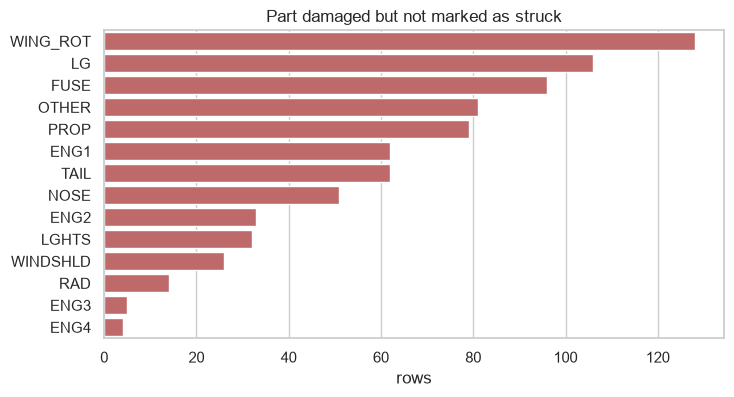

In [31]:
violations = pd.Series((dam > struck).sum(axis=0), index=parts).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=violations.values, y=violations.index, color="indianred")
ax.set(title="Part damaged but not marked as struck", xlabel="rows", ylabel="")
plt.show()

About 460 rows have damage or ingestion without a strike, probably the struck box was not ticked. 14 strikes are on an engine the aircraft doesn't have.

The chart splits the damaged-not-struck cases by part: wing/rotor, landing gear and fuselage lead, they are the big parts that are struck most often anyway. No part stands out, so it is a form-filling habit, not a broken column.

In [32]:
pd.crosstab(df["AIRPORT_ID"] == "ZZZZ", lat.isna(), rownames=["unknown airport"], colnames=["no coordinates"])

no coordinates,False,True
unknown airport,,
False,275891,90
True,0,40858


Coordinates are missing mostly because the airport is unknown. 90 rows have a known airport and no coordinates, they can be filled from an airport table.

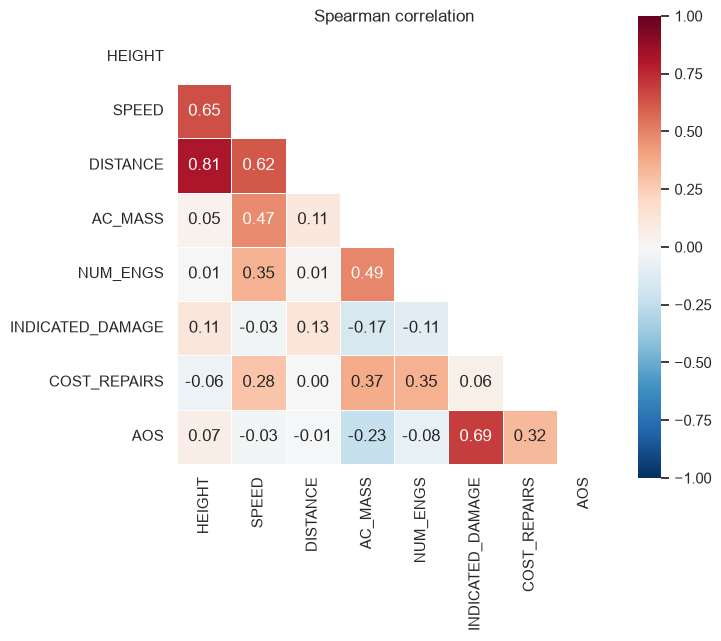

In [33]:
corr_cols = ["HEIGHT", "SPEED", "DISTANCE", "AC_MASS", "NUM_ENGS", "INDICATED_DAMAGE", "COST_REPAIRS", "AOS"]
corr = df[corr_cols].corr(method="spearman")
upper = np.triu(np.ones_like(corr, dtype=bool))  # the matrix is symmetric, show only one half

plt.figure(figsize=(7, 6))
with sns.axes_style("white"):  # no grid lines over the cells
    sns.heatmap(corr, mask=upper, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Spearman correlation")
plt.show()

Height goes with distance and speed, heavier aircraft have more engines. AOS (hours out of service) goes with INDICATED_DAMAGE, which is logical. Nothing suspicious.

## 7. Data quality metrics

In [34]:
n = len(df)

# completeness on the fields every report should have, placeholders count as missing
must_have = pd.DataFrame({
    "TIME": df["TIME"].notna() & ~time_blank,
    "AIRPORT_ID": df["AIRPORT_ID"] != "ZZZZ",
    "OPID": df["OPID"] != "UNK",
    "AIRCRAFT": ~df["AIRCRAFT"].str.contains("UNKNOWN", na=False),
    "PHASE_OF_FLIGHT": df["PHASE_OF_FLIGHT"].notna(),
    "INCIDENT_DATE": df["INCIDENT_DATE"].notna(),
    "SPECIES_ID": df["SPECIES_ID"].notna(),
    "NUM_STRUCK": df["NUM_STRUCK"].notna(),
    "INDICATED_DAMAGE": df["INDICATED_DAMAGE"].notna(),
    "SOURCE": df["SOURCE"].notna(),
    "INDEX_NR": df["INDEX_NR"].notna(),
})

valid = ~bad_coords & ~updated_before & ~df["PRECIPITATION"].str.contains("None,|, None", na=False) \
        & ~(df["HEIGHT"] > 50_000) & ~(df["SPEED"] > 600)

time_values = df["TIME"].dropna()
ac_class = df["AC_CLASS"].dropna()
conforming = time_values.str.fullmatch(r"\d{1,2}:\d{2}").sum() + (ac_class == ac_class.str.strip()).sum()
conformity = conforming / (len(time_values) + len(ac_class))

consistent = ~damaged_not_struck & ~ingested_not_struck & ~wrong_engine & ~night_at_noon & ~day_at_night

metrics = pd.DataFrame([
    ["Completeness, all columns", df.notna().mean().mean(), ">= 0.98"],
    ["Completeness, must-have columns", must_have.mean().mean(), ">= 0.98"],
    ["Uniqueness of INDEX_NR", df["INDEX_NR"].nunique() / n, "= 1"],
    ["Duplication rate", df.drop(columns="INDEX_NR").duplicated().mean(), "<= 0.01"],
    ["Validity", valid.mean(), ">= 0.99"],
    ["Conformity (TIME, AC_CLASS)", conformity, ">= 0.99"],
    ["Consistency", consistent.mean(), ">= 0.98"],
    ["Integrity (known airport has coords)", lat[df["AIRPORT_ID"] != "ZZZZ"].notna().mean(), ">= 0.99"],
    ["Outlier ratio (IQR)", outliers["outlier share"].mean(), "<= 0.02"],
], columns=["metric", "value", "target"]).set_index("metric")
metrics["value"] = metrics["value"].round(4)
metrics

,value,target
metric,,
"Completeness, all columns",0.7513,>= 0.98
"Completeness, must-have columns",0.8619,>= 0.98
Uniqueness of INDEX_NR,1.0000,= 1
Duplication rate,0.0002,<= 0.01
Validity,0.9999,>= 0.99
"Conformity (TIME, AC_CLASS)",0.4283,>= 0.99
Consistency,0.9930,>= 0.98
Integrity (known airport has coords),0.9997,>= 0.99
Outlier ratio (IQR),0.1295,<= 0.02


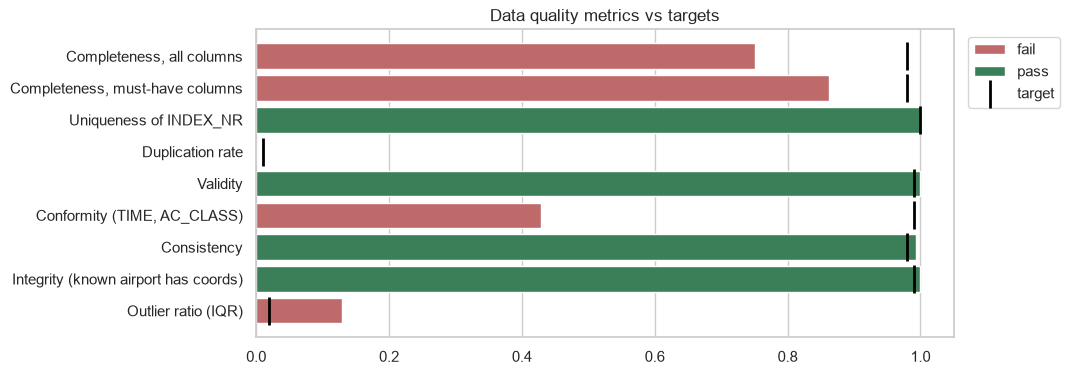

In [35]:
# turn the target text into a number and a direction to colour the bars
target = metrics["target"].str.extract(r"(?P<op>[<>=]+)\s*(?P<limit>[\d.]+)")
target["limit"] = target["limit"].astype(float)
passed = np.select([target["op"] == ">=", target["op"] == "<="],
                   [metrics["value"] >= target["limit"], metrics["value"] <= target["limit"]],
                   metrics["value"] == target["limit"])
chart = metrics.assign(limit=target["limit"], status=np.where(passed, "pass", "fail")).reset_index()

plt.figure(figsize=(9, 4))
ax = sns.barplot(data=chart, y="metric", x="value", hue="status", palette={"pass": "seagreen", "fail": "indianred"})
sns.scatterplot(data=chart, y="metric", x="limit", marker="|", s=400, linewidth=2, color="black", label="target", ax=ax)
ax.set(title="Data quality metrics vs targets", xlabel="", ylabel="", xlim=(0, 1.05))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

In [36]:
lag = (lupdate - dates).dt.days
print("timeliness, days from strike to last update:", lag.quantile([0.5, 0.9]).to_dict())
print(must_have.mean().round(2).sort_values().head(5))

timeliness, days from strike to last update: {0.5: 132.0, 0.9: 2379.0}
TIME               0.57
PHASE_OF_FLIGHT    0.61
OPID               0.72
AIRCRAFT           0.72
AIRPORT_ID         0.87
dtype: float64


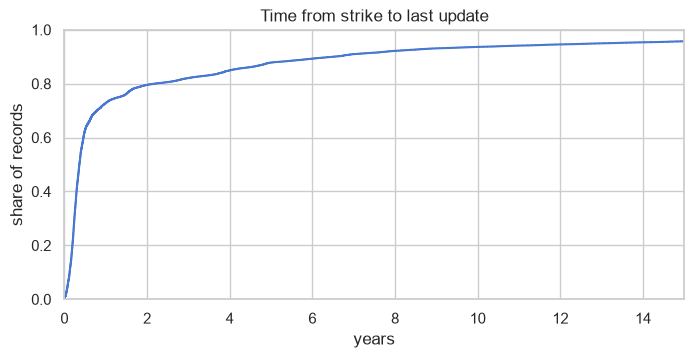

In [37]:
plt.figure(figsize=(8, 3.5))
ax = sns.ecdfplot(lag[lag >= 0] / 365.25)
ax.set(title="Time from strike to last update", xlabel="years", ylabel="share of records", xlim=(0, 15))
plt.show()

On the chart red bars are failing metrics and the black tick is the target. The duplication rate (0.0002) is too small to see as a bar, but it passes.

Uniqueness, duplicates, validity, consistency and integrity pass. Completeness fails (0.75 overall, 0.86 on must-have fields), mostly because of time, flight phase, operator and aircraft. Conformity fails because of the spaces in AC_CLASS and TIME. The outlier ratio fails, but I explained above why IQR doesn't fit.

Timeliness: half of the records get their last update within 4 months and 73% within a year, but 12% are changed more than 5 years after the strike. So old records are not final, and the loader must be able to update them. Accuracy can't be checked without a reference source.


## 8. Recommendations for the ETL pipeline

- cast types, convert or drop broken coordinates
- trim strings, turn blanks and unknown codes into NaN
- drop constant columns and the 61 duplicates
- split multi-value fields, make NUM_SEEN and NUM_STRUCK ordered categories
- set struck to 1 where a part is damaged
- flag contradictions instead of fixing them, check TIME for the 12-hour format
- check outliers by range per flight phase and on log scale for costs, not by IQR on the whole column
- don't use the last months of the export for trends, they are incomplete
- load with upsert by INDEX_NR, because old records keep changing

## 9. Conclusions

The data has a good structure and few logical errors. The main problem is missing flight data, and it comes from the source, ETL can only document it. Format issues are small and easy to clean. Most extreme values are real.